# Video Game Sales Analysis
Portfolio copy of completed TripleTen coursework. Saved numeric outputs are from the supplied notebook; edits to wording, paths, display, and units have not been rerun against the source CSV. Sales are in millions of copies. Charts with incorrect original unit labels were cleared; rerun to regenerate them.


# Video Game Sales Analysis Project
## Project Overview

In this project, you'll analyze video game sales data to identify patterns that determine a game's success. Working as an analyst for the online store Ice, you'll use this information to help plan future advertising campaigns.

## Environment Setup and Required Libraries

In [23]:
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt

from scipy import stats

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 200)



## Step 1: Loading and Initial Data Exploration

First, let's load our dataset and examine its basic properties:

In [24]:
from pathlib import Path
import os
from IPython.display import display

data_path = Path(os.environ.get('GAMES_DATA_PATH', 'data/games.csv'))
if not data_path.exists() and Path('/datasets/games.csv').exists():
    data_path = Path('/datasets/games.csv')
if not data_path.exists():
    raise FileNotFoundError('Place games.csv in data/ or set GAMES_DATA_PATH.')
games = pd.read_csv(data_path)
games.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [25]:
games.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [26]:
# Check for duplicate rows
duplicate_count = games.duplicated().sum()
duplicate_count


0

### Key Questions to Answer:
- What's the total number of records in our dataset?
- What data types are present in each column?
- Are there any obvious issues with the data?
- Do we see any immediate patterns or anomalies?

The dataset contains **16,715 game-platform release records** and 11 original columns, as shown by the saved `info()` output.

2. What data types are present in each column?
Based on the initial inspection using info(), the dataset contains the following data types:
Object (categorical/text):
Name
Platform
Genre
Rating
User_Score
Numeric (float / int):
Year_of_Release (appears as float due to missing values)
NA_sales
EU_sales
JP_sales
Other_sales
Critic_Score
Several columns that should logically be numeric (User_Score, Year_of_Release) are not yet in their optimal data types, which will be addressed during data preparation.

3. Are there any obvious issues with the data?
Yes, several data quality issues are immediately apparent:
Missing values:
Review scores (Critic_Score, User_Score)
ESRB ratings (Rating)
Release years (Year_of_Release)
Incorrect data types:
User_Score contains non-numeric values such as "TBD", causing it to be read as an object.
Year_of_Release is stored as a float rather than an integer.
Potential incompleteness:
Sales data for 2016 may be incomplete, which could affect trend analysis and forecasting.
These issues must be handled carefully to avoid biased or misleading analytical results.

4. Do we see any immediate patterns or anomalies?
Several early observations can be made:
Sales values are heavily right-skewed, indicating that a small number of blockbuster titles generate disproportionately high sales.
There is significant variation in sales across platforms and regions, suggesting strong regional preferences.
Many games have missing user or critic scores, likely due to limited reviews, regional releases, or timing of data collection.
Some platforms appear frequently while others have very few entries, hinting at platform life cycles and shifts in market dominance over time.

## Step 2: Data Preparation

### 2.1 Standardizing Column Names

In [27]:
games.columns = games.columns.str.lower()
games.columns


Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='object')

### 2.2 Data Type Conversion

In [29]:
games.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  float64
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       10014 non-null  object 
 10  rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [30]:
# Replace 'TBD' values with NaN
games['user_score'] = games['user_score'].replace(['TBD', 'tbd'], np.nan)


In [31]:
# Convert user_score and critic_score to numeric types
games['user_score'] = pd.to_numeric(games['user_score'], errors='coerce')
games['critic_score'] = pd.to_numeric(games['critic_score'], errors='coerce')

# Convert year_of_release to nullable integer
games['year_of_release'] = pd.to_numeric(
    games['year_of_release'], errors='coerce'
).astype('Int64')

# Verify changes
games.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           9949 non-null   object 
dtypes: Int64(1), float64(6), object(4)
memory usage: 1.4+ MB


### 2.3 Handling Missing Values

In [32]:
# Count missing values per column
missing_counts = games.isna().sum()
missing_counts


name                  2
platform              0
year_of_release     269
genre                 2
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8578
user_score         9125
rating             6766
dtype: int64

In [33]:
# Calculate percentage of missing values
missing_percent = (games.isna().mean() * 100).round(2)
missing_percent

# Percentage of missing values by column
(games.isna().mean() * 100).round(2).sort_values(ascending=False)



user_score         54.59
critic_score       51.32
rating             40.48
year_of_release     1.61
name                0.01
genre               0.01
platform            0.00
na_sales            0.00
eu_sales            0.00
jp_sales            0.00
other_sales         0.00
dtype: float64

In [35]:
# No imputation is applied to score or rating columns.
# Missing values will be handled contextually during analysis.

games.isna().sum()



name                  2
platform              0
year_of_release     269
genre                 2
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8578
user_score         9125
rating             6766
dtype: int64

The dataset does not establish why every value is missing. Unavailable reviews, regional rating practices, and collection timing are possible explanations; these remain hypotheses. `tbd` denotes an unavailable user score.

How were missing values handled and why?
Review scores (user_score, critic_score) were left as NaN to avoid introducing bias into correlations and hypothesis tests.
"TBD" values were replaced with NaN because they represent unavailable data, not numeric scores.
ESRB ratings were left missing to avoid creating misleading categorical data.
Year of release values were kept as missing and excluded only from time-based analyses.
Sales data required no imputation, as no significant missing values were observed.

### 2.4 Calculate Total Sales

In [36]:
# Ensure regional sales columns are numeric
regions = ['na_sales', 'eu_sales', 'jp_sales', 'other_sales']
games[regions] = games[regions].apply(pd.to_numeric, errors='coerce')

# Calculate global (total) sales
games['total_sales'] = games[regions].sum(axis=1)

# Verify regional and total sales
games[['name', 'platform', 'na_sales', 'eu_sales', 'jp_sales', 'other_sales', 'total_sales']].head()



,name,platform,na_sales,eu_sales,jp_sales,other_sales,total_sales
0,Wii Sports,Wii,41.36,28.96,3.77,8.45,82.54
1,Super Mario Bros.,NES,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,Wii,15.68,12.76,3.79,3.29,35.52
3,Wii Sports Resort,Wii,15.61,10.93,3.28,2.95,32.77
4,Pokemon Red/Pokemon Blue,GB,11.27,8.89,10.22,1.00,31.38


# Step 3: Analyzing Video Game Sales Data

## 3.1 Temporal Analysis of Game Releases
Let's first examine the distribution of game releases across different years to understand our data's coverage and significance:

In [37]:
# Count number of game releases per year
games_by_year = (
    games.dropna(subset=['year_of_release'])
         .groupby('year_of_release')['name']
         .count()
         .reset_index(name='games_released')
)

games_by_year.head()


,year_of_release,games_released
0,1980,9
1,1981,46
2,1982,36
3,1983,17
4,1984,14


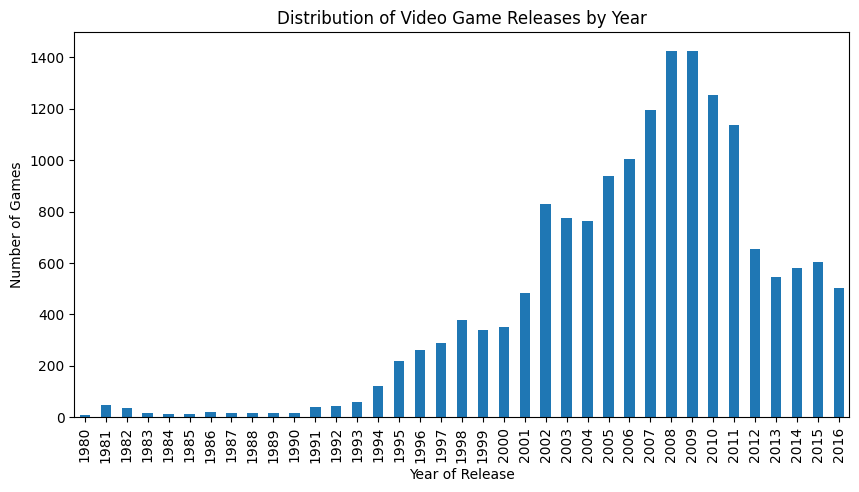

In [38]:
import matplotlib.pyplot as plt

# Aggregate number of games released per year
games_by_year = (
    games.dropna(subset=['year_of_release'])
         .groupby('year_of_release')['name']
         .count()
)

# Plot distribution
plt.figure(figsize=(10, 5))
games_by_year.plot(kind='bar')
plt.title('Distribution of Video Game Releases by Year')
plt.xlabel('Year of Release')
plt.ylabel('Number of Games')
plt.show()


In [39]:
# Summary statistics of sales by year
yearly_stats = (
    games.dropna(subset=['year_of_release'])
         .groupby('year_of_release')['total_sales']
         .describe()
)

yearly_stats


,count,mean,std,min,25%,50%,75%,max
year_of_release,,,,,,,,
1980,9.0,1.264444,1.383547,0.23,0.3400,0.770,1.1500,4.31
1981,46.0,0.775652,0.783019,0.13,0.3125,0.465,0.9525,4.50
1982,36.0,0.802222,1.257910,0.14,0.3350,0.540,0.7800,7.81
1983,17.0,0.988235,0.838825,0.16,0.4000,0.770,1.1300,3.20
1984,14.0,3.596429,7.200795,0.27,1.1300,1.485,2.0900,28.31
1985,14.0,3.853571,10.510376,0.02,0.4650,1.015,1.4550,40.24
1986,21.0,1.765714,1.328001,0.30,1.1500,1.360,2.2000,6.50
1987,16.0,1.356250,1.225174,0.07,0.4550,0.885,2.2125,4.38
1988,15.0,3.147333,4.414414,0.03,0.9700,1.510,3.1450,17.28


### Questions to Consider:
- Which years show significant numbers of game releases?
- Are there any notable trends or patterns in the number of releases?
- Is there enough recent data to make predictions for 2017?

The release-year charts describe historical coverage, not a uniformly increasing trend. The recent analysis uses 2013–2016 (2,233 records). Because 2016 may be incomplete, year-over-year declines involving that year require caution.

## 3.2 Platform Sales Analysis Over Time

Now let's analyze how sales vary across platforms and years:

In [40]:
# Calculate total sales by platform and year
platform_year_sales = (
    games.dropna(subset=['year_of_release'])
         .groupby(['year_of_release', 'platform'])['total_sales']
         .sum()
         .reset_index()
)

platform_year_sales.head()


,year_of_release,platform,total_sales
0,1980,2600,11.38
1,1981,2600,35.68
2,1982,2600,28.88
3,1983,2600,5.84
4,1983,NES,10.96


In [ ]:
# Recreate platform sales pivot table
platform_year_pivot = (
    games.dropna(subset=['year_of_release'])
         .groupby(['year_of_release', 'platform'])['total_sales']
         .sum()
         .reset_index()
         .pivot(index='year_of_release', columns='platform', values='total_sales')
         .fillna(0)
         .sort_index()
)

platform_year_pivot.head()


import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
plt.imshow(platform_year_pivot, aspect='auto')
plt.colorbar(label='Total Sales (million copies)')

plt.xticks(
    ticks=range(len(platform_year_pivot.columns)),
    labels=platform_year_pivot.columns,
    rotation=90
)
plt.yticks(
    ticks=range(len(platform_year_pivot.index)),
    labels=platform_year_pivot.index
)

plt.title('Heatmap of Platform Sales Over Time')
plt.xlabel('Platform')
plt.ylabel('Year of Release')
plt.show()


In [44]:
# Aggregate sales by platform and year
platform_year_sales = (
    games.dropna(subset=['year_of_release'])
         .groupby(['year_of_release', 'platform'])['total_sales']
         .sum()
         .reset_index()
)

# Focus on the most recent years in the dataset
recent_years = sorted(platform_year_sales['year_of_release'].unique())[-3:]

recent_sales = (
    platform_year_sales[platform_year_sales['year_of_release'].isin(recent_years)]
    .pivot(index='platform', columns='year_of_release', values='total_sales')
    .fillna(0)
)

recent_sales


# Identify platforms with declining sales over recent years
declining_platforms = recent_sales[
    (recent_sales[recent_years[0]] > recent_sales[recent_years[1]]) &
    (recent_sales[recent_years[1]] > recent_sales[recent_years[2]])
]

declining_platforms



year_of_release,2014,2015,2016
platform,,,
3DS,43.76,27.78,15.14
PC,13.28,8.52,5.25
PS3,47.76,16.82,3.60
PSP,0.24,0.12,0.00
PSV,11.90,6.25,4.25
Wii,3.75,1.14,0.18
WiiU,22.03,16.35,4.60
X360,34.74,11.96,1.52


### Questions to Consider:
- Which platforms show consistent sales over time?
- Can you identify platforms that have disappeared from the market?
- What's the typical lifecycle of a gaming platform?

PS4 and Xbox One are candidates for the historical 2017 planning exercise based on their recent sales and generation relevance. The saved table also shows PC sales declining from 13.28 million copies in 2014 to 8.52 in 2015 and 5.25 in 2016; PC should not be described as stable. Near-zero recorded sales do not establish that a platform has disappeared from the market. Platform lifecycles vary, and partial 2016 data limits comparisons.

## 3.3 Determining Relevant Time Period

Based on your analysis above, determine the appropriate time period for predicting 2017 sales:

In [45]:
# Define relevant years for forecasting 2017 sales
relevant_years = [2013, 2014, 2015, 2016]

# Filter dataset to relevant years
df_relevant = games[games['year_of_release'].isin(relevant_years)].copy()

# Verify filtering
df_relevant['year_of_release'].value_counts().sort_index()


2013    544
2014    581
2015    606
2016    502
Name: year_of_release, dtype: Int64

### Document Your Decision:
- What years did you select and why?
- How does this period reflect current market conditions?
- What factors influenced your decision?

I selected **2013–2016** to focus on recent platform generations for the original 2017 marketing-planning scenario. The subset contains 2,233 release records. This is an exploratory analysis; no forecast model or forecast-accuracy evaluation is implemented. Possible incomplete 2016 coverage limits trend interpretation.

## 3.4 Platform Performance Analysis

Using your selected time period, let's analyze platform performance:

In [ ]:
# Total sales by platform in the relevant period
platform_sales = (
    df_relevant.groupby('platform')['total_sales']
               .sum()
               .sort_values(ascending=False)
)

platform_sales

# Platform sales trends over time (relevant period only)
platform_year_trends = (
    df_relevant.groupby(['year_of_release', 'platform'])['total_sales']
               .sum()
               .reset_index()
               .pivot(index='year_of_release', columns='platform', values='total_sales')
               .fillna(0)
               .sort_index()
)

platform_year_trends

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
platform_year_trends.plot(ax=plt.gca())
plt.title('Platform Sales Trends (2013–2016)')
plt.xlabel('Year of Release')
plt.ylabel('Total Sales (million copies)')
plt.legend(title='Platform', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()



In [48]:
# Sort platforms by total sales in the relevant period
platform_sales_sorted = (
    df_relevant.groupby('platform')['total_sales']
               .sum()
               .sort_values(ascending=False)
)

platform_sales_sorted


platform
PS4     314.14
PS3     181.43
XOne    159.32
3DS     143.25
X360    136.80
WiiU     64.63
PC       39.43
PSV      32.99
Wii      13.66
PSP       3.50
DS        1.54
Name: total_sales, dtype: float64

In [ ]:
import matplotlib.pyplot as plt

# Select top 5 platforms by total sales
top_platforms = (
    df_relevant.groupby('platform')['total_sales']
               .sum()
               .sort_values(ascending=False)
               .head(5)
)

# Bar chart of top platforms
plt.figure(figsize=(8, 5))
top_platforms.plot(kind='bar')
plt.title('Top 5 Platforms by Total Sales (2013–2016)')
plt.xlabel('Platform')
plt.ylabel('Total Sales (million copies)')
plt.show()

# Aggregate sales by year and platform
platform_year_sales = (
    df_relevant.groupby(['year_of_release', 'platform'])['total_sales']
               .sum()
               .reset_index()
)

# Pivot table
platform_year_pivot = platform_year_sales.pivot(
    index='year_of_release',
    columns='platform',
    values='total_sales'
).fillna(0).sort_index()

platform_year_pivot

# Calculate year-over-year growth rates
platform_yoy_growth = platform_year_pivot.pct_change() * 100

platform_yoy_growth

# Plot YoY growth for top platforms only
plt.figure(figsize=(12, 6))
platform_yoy_growth[top_platforms.index].plot(ax=plt.gca(), marker='o')
plt.axhline(0)
plt.title('Year-over-Year Sales Growth by Platform (2013–2016)')
plt.xlabel('Year')
plt.ylabel('Growth Rate (%)')
plt.legend(title='Platform', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()


## 3.5 Sales Distribution Analysis

Let's examine the distribution of sales across platforms:

In [ ]:
import matplotlib.pyplot as plt

# Select top platforms for clearer visualization
top_platforms = (
    df_relevant.groupby('platform')['total_sales']
               .sum()
               .sort_values(ascending=False)
               .head(6)
               .index
)

# Box plot of total sales by platform
plt.figure(figsize=(12, 6))
df_relevant[df_relevant['platform'].isin(top_platforms)].boxplot(
    column='total_sales',
    by='platform'
)

plt.title('Distribution of Global Game Sales by Platform (2013–2016)')
plt.suptitle('')
plt.xlabel('Platform')
plt.ylabel('Total Sales (million copies)')
plt.show()


In [51]:
# Calculate detailed statistics for each platform
platform_stats = (
    df_relevant.groupby('platform')['total_sales']
               .describe()
               .sort_values(by='mean', ascending=False)
)

platform_stats


,count,mean,std,min,25%,50%,75%,max
platform,,,,,,,,
PS4,392.0,0.801378,1.609456,0.01,0.0600,0.200,0.7300,14.63
X360,186.0,0.735484,1.663275,0.01,0.0800,0.265,0.7950,16.27
XOne,247.0,0.645020,1.036139,0.01,0.0600,0.220,0.6850,7.39
Wii,23.0,0.593913,0.915432,0.01,0.0450,0.180,0.7550,3.58
WiiU,115.0,0.562000,1.038778,0.01,0.0600,0.200,0.5950,7.09
PS3,345.0,0.525884,1.451939,0.01,0.0400,0.150,0.5100,21.05
3DS,303.0,0.472772,1.381347,0.01,0.0400,0.090,0.2800,14.60
PC,189.0,0.208624,0.352304,0.01,0.0300,0.080,0.2300,3.05
DS,8.0,0.192500,0.172026,0.03,0.0675,0.150,0.2525,0.51


## 3.6 Review Score Impact Analysis

Select a popular platform and analyze how reviews affect sales:

In [ ]:


# Critic Scores: remove missing values
critic_df = platform_data.dropna(subset=['critic_score', 'total_sales'])

plt.figure(figsize=(7, 5))
plt.scatter(critic_df['critic_score'], critic_df['total_sales'])
plt.title(f'{popular_platform}: Critic Score vs Total Sales')
plt.xlabel('Critic Score')
plt.ylabel('Total Sales (million copies)')
plt.show()





# User Scores: remove missing values
user_df = platform_data.dropna(subset=['user_score', 'total_sales'])

plt.figure(figsize=(7, 5))
plt.scatter(user_df['user_score'], user_df['total_sales'])
plt.title(f'{popular_platform}: User Score vs Total Sales')
plt.xlabel('User Score')
plt.ylabel('Total Sales (million copies)')
plt.show()



# Calculate Pearson correlation coefficients
critic_corr = critic_df['critic_score'].corr(critic_df['total_sales'])
user_corr = user_df['user_score'].corr(user_df['total_sales'])

critic_corr, user_corr




## 3.7 Cross-Platform Comparison

Compare sales performance of games across different platforms:

In [56]:
# Count number of platforms per game
games_platform_count = (
    df_relevant.groupby('name')['platform']
               .nunique()
               .reset_index(name='platform_count')
)

# Filter games released on more than one platform
multi_platform_games = games_platform_count[
    games_platform_count['platform_count'] > 1
]

multi_platform_games.head()


,name,platform_count
2,Frozen: Olaf's Quest,2
8,2014 FIFA World Cup Brazil,2
10,3rd Super Robot Wars Z Jigoku Hen,2
11,3rd Super Robot Wars Z: Tengoku-Hen,2
13,7 Days to Die,2


In [ ]:
# Recreate multi-platform games list
games_platform_count = (
    df_relevant.groupby('name')['platform']
               .nunique()
               .reset_index(name='platform_count')
)

multi_platform_games = games_platform_count[
    games_platform_count['platform_count'] > 1
]['name']

# Filter dataset to multi-platform games
multi_df = df_relevant[df_relevant['name'].isin(multi_platform_games)].copy()

multi_df.head()

cross_platform_sales = (
    multi_df.pivot_table(
        index='name',
        columns='platform',
        values='total_sales',
        aggfunc='sum'
    )
)

cross_platform_sales.head()

# Select top-selling multi-platform games
top_multi_games = (
    multi_df.groupby('name')['total_sales']
            .sum()
            .sort_values(ascending=False)
            .head(10)
            .index
)

# Plot sales comparison
cross_platform_sales.loc[top_multi_games].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Sales Comparison of Top Multi-Platform Games')
plt.xlabel('Game Title')
plt.ylabel('Total Sales (million copies)')
plt.legend(title='Platform', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()



## 3.8 Genre Analysis

Finally, let's examine the distribution of games by genre:

In [59]:
# Aggregate genre performance metrics
genre_performance = (
    df_relevant.groupby('genre')['total_sales']
               .agg(
                   games_count='count',
                   total_sales='sum',
                   avg_sales='mean',
                   median_sales='median',
                   sales_std='std'
               )
               .sort_values(by='total_sales', ascending=False)
)

genre_performance


,games_count,total_sales,avg_sales,median_sales,sales_std
genre,,,,,
Action,766,321.87,0.420196,0.110,1.253909
Shooter,187,232.98,1.245882,0.450,2.014107
Sports,214,150.65,0.703972,0.240,1.219237
Role-Playing,292,145.89,0.499623,0.125,1.353164
Misc,155,62.82,0.405290,0.100,1.007985
Platform,74,42.63,0.576081,0.225,0.806808
Racing,85,39.89,0.469294,0.120,0.964101
Fighting,80,35.31,0.441375,0.125,1.048883
Adventure,245,23.64,0.096490,0.030,0.216445


In [60]:
# Sort genres by total sales (descending)
genres_by_total_sales = (
    df_relevant.groupby('genre')['total_sales']
               .sum()
               .sort_values(ascending=False)
)

genres_by_total_sales


genre
Action          321.87
Shooter         232.98
Sports          150.65
Role-Playing    145.89
Misc             62.82
Platform         42.63
Racing           39.89
Fighting         35.31
Adventure        23.64
Simulation       21.76
Strategy         10.08
Puzzle            3.17
Name: total_sales, dtype: float64

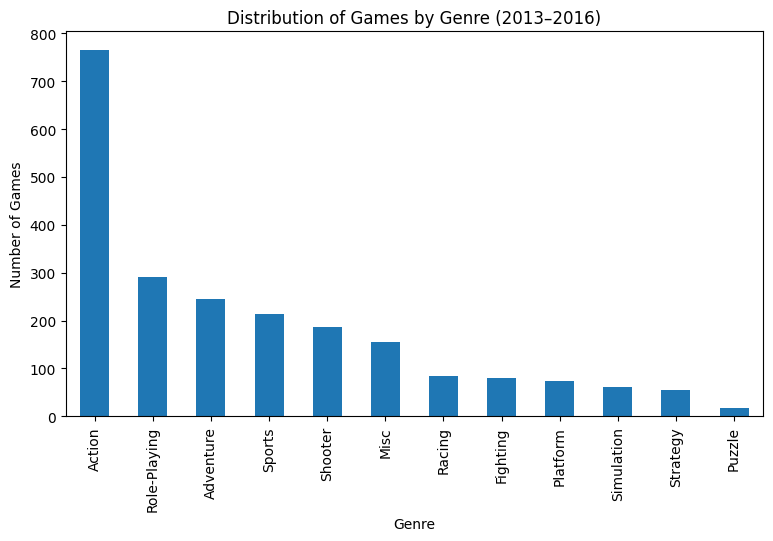

In [61]:
import matplotlib.pyplot as plt

# Distribution of games by genre
genre_counts = df_relevant['genre'].value_counts()

plt.figure(figsize=(9, 5))
genre_counts.plot(kind='bar')
plt.title('Distribution of Games by Genre (2013–2016)')
plt.xlabel('Genre')
plt.ylabel('Number of Games')
plt.show()


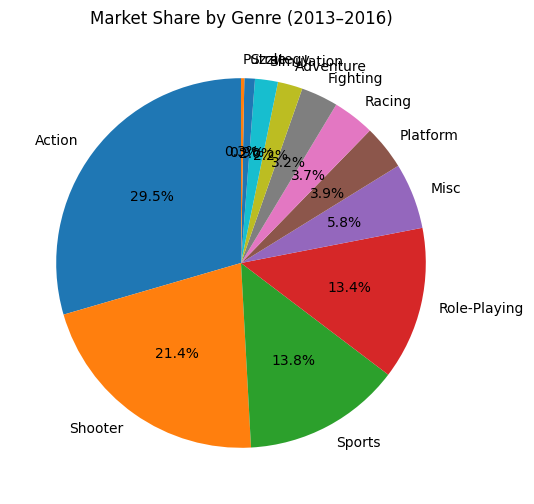

In [63]:
# Recalculate total market sales
total_market_sales = df_relevant['total_sales'].sum()

# Calculate market share by genre
genre_market_share = (
    df_relevant.groupby('genre')['total_sales']
               .sum()
               .div(total_market_sales)
               .mul(100)
               .round(2)
               .sort_values(ascending=False)
)

genre_market_share

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
genre_market_share.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Market Share by Genre (2013–2016)')
plt.ylabel('')
plt.show()



### Key Questions for Genre Analysis:
- Which genres consistently perform well?
- Are there any genres showing recent growth or decline?
- How does the average performance vary across genres?

Action has the highest recorded total sales (321.87 million copies), while Shooter has the highest mean (1.246 million copies) and median (0.450 million copies) among the displayed genres. Action’s median is 0.110 million copies, illustrating how total volume and typical title performance differ. These aggregates do not establish growth trends or profitability because costs and prices are unavailable.

# Step 4: Regional Market Analysis and User Profiles

In this section, we will analyze the gaming market characteristics across three major regions: North America (NA), Europe (EU), and Japan (JP). Our analysis will focus on platform preferences, genre popularity, and the impact of ESRB ratings in each region.

## 4.1 Regional Platform Analysis

Let's begin by examining platform performance across different regions:

In [64]:
import pandas as pd

def platform_performance_by_region(df, region_col, top_n=5):
    """
    Returns a DataFrame with total sales and market share by platform for a given region.
    """
    platform_sales = (
        df.groupby('platform')[region_col]
          .sum()
          .sort_values(ascending=False)
    )
    
    total_sales = platform_sales.sum()
    platform_share = (platform_sales / total_sales * 100).round(2)
    
    result = pd.DataFrame({
        'total_sales': platform_sales,
        'market_share_%': platform_share
    }).head(top_n)
    
    return result



In [ ]:
na_platforms = platform_performance_by_region(df_relevant, 'na_sales', top_n=5)
na_platforms

eu_platforms = platform_performance_by_region(df_relevant, 'eu_sales', top_n=5)
eu_platforms

jp_platforms = platform_performance_by_region(df_relevant, 'jp_sales', top_n=5)
jp_platforms


display(na_platforms, eu_platforms, jp_platforms)


### Cross-Regional Platform Comparison

Let's create a comparative analysis of platform performance across regions:

In [ ]:
# Aggregate platform sales by region
platform_comparison = (
    df_relevant.groupby('platform')[['na_sales', 'eu_sales', 'jp_sales']]
               .sum()
)

# Add NA/EU/JP total (excludes other_sales)
platform_comparison['three_region_sales'] = (
    platform_comparison['na_sales']
    + platform_comparison['eu_sales']
    + platform_comparison['jp_sales']
)

# Sort by combined NA/EU/JP sales
platform_comparison = platform_comparison.sort_values(
    by='global_sales', ascending=False
)

platform_comparison.head(10)


In [ ]:
import matplotlib.pyplot as plt

# Identify top platforms by global sales
top_platforms = (
    df_relevant.groupby('platform')['total_sales']
               .sum()
               .sort_values(ascending=False)
               .head(5)
               .index
)

# Aggregate regional sales for top platforms
top_platforms_region_sales = (
    df_relevant[df_relevant['platform'].isin(top_platforms)]
    .groupby('platform')[['na_sales', 'eu_sales', 'jp_sales']]
    .sum()
)

top_platforms_region_sales

top_platforms_region_sales.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Cross-Regional Sales Comparison for Top Platforms (2013–2016)')
plt.xlabel('Platform')
plt.ylabel('Total Sales (million copies)')
plt.legend(['North America', 'Europe', 'Japan'])
plt.show()


## 4.2 Regional Genre Analysis

Now let's examine genre preferences across regions:

In [70]:
# Ensure the function exists (safe to re-run)
def genre_performance_by_region(df, region_col, top_n=5):
    genre_sales = (
        df.groupby('genre')[region_col]
          .sum()
          .sort_values(ascending=False)
    )
    
    total_sales = genre_sales.sum()
    genre_share = (genre_sales / total_sales * 100).round(2)
    
    return pd.DataFrame({
        'total_sales': genre_sales,
        'market_share_%': genre_share
    }).head(top_n)

# Create genre performance tables for each region
na_genres = genre_performance_by_region(df_relevant, 'na_sales', top_n=5)
eu_genres = genre_performance_by_region(df_relevant, 'eu_sales', top_n=5)
jp_genres = genre_performance_by_region(df_relevant, 'jp_sales', top_n=5)

# Display results
display(na_genres, eu_genres, jp_genres)




,total_sales,market_share_%
genre,,
Action,126.05,28.80
Shooter,109.74,25.07
Sports,65.27,14.91
Role-Playing,46.40,10.60
Misc,27.49,6.28


,total_sales,market_share_%
genre,,
Action,118.13,30.12
Shooter,87.86,22.40
Sports,60.52,15.43
Role-Playing,36.97,9.43
Racing,20.19,5.15


,total_sales,market_share_%
genre,,
Role-Playing,51.04,36.26
Action,40.49,28.76
Misc,9.20,6.54
Fighting,7.65,5.43
Shooter,6.61,4.70


### Cross-Regional Genre Comparison

Let's compare genre preferences across regions:

In [ ]:
# Aggregate genre sales by region
genre_comparison = (
    df_relevant.groupby('genre')[['na_sales', 'eu_sales', 'jp_sales']]
               .sum()
)

# Add NA/EU/JP total (excludes other_sales)
genre_comparison['three_region_sales'] = (
    genre_comparison['na_sales']
    + genre_comparison['eu_sales']
    + genre_comparison['jp_sales']
)

# Sort by combined NA/EU/JP sales
genre_comparison = genre_comparison.sort_values(
    by='global_sales', ascending=False
)

genre_comparison.head(10)



## 4.3 ESRB Rating Impact Analysis

Finally, let's examine how ESRB ratings affect sales in each region:

In [74]:
# Ensure the function exists (safe to re-run)
def esrb_impact_by_region(df, region_col, top_n=10, include_missing=True):
    tmp = df.copy()
    
    if include_missing:
        tmp['rating'] = tmp['rating'].fillna('Unknown')
    else:
        tmp = tmp.dropna(subset=['rating'])
    
    rating_sales = (
        tmp.groupby('rating')[region_col]
           .sum()
           .sort_values(ascending=False)
    )
    
    total_sales = rating_sales.sum()
    rating_share = (rating_sales / total_sales * 100).round(2)
    
    return pd.DataFrame({
        'total_sales': rating_sales,
        'market_share_%': rating_share
    }).head(top_n)

# Create ESRB impact tables for each region
na_ratings = esrb_impact_by_region(df_relevant, 'na_sales', top_n=10, include_missing=True)
eu_ratings = esrb_impact_by_region(df_relevant, 'eu_sales', top_n=10, include_missing=True)
jp_ratings = esrb_impact_by_region(df_relevant, 'jp_sales', top_n=10, include_missing=True)

# Display results
display(na_ratings, eu_ratings, jp_ratings)




,total_sales,market_share_%
rating,,
M,165.21,37.74
Unknown,89.42,20.43
E,79.05,18.06
E10+,54.24,12.39
T,49.79,11.38


,total_sales,market_share_%
rating,,
M,145.32,37.05
E,83.36,21.25
Unknown,78.91,20.12
E10+,42.69,10.88
T,41.95,10.70


,total_sales,market_share_%
rating,,
Unknown,85.05,60.41
T,20.59,14.63
E,15.14,10.75
M,14.11,10.02
E10+,5.89,4.18


# Step 5 : Hypothesis Tests

—Average user ratings of the Xbox One and PC platforms are the same.

—Average user ratings for the Action and Sports genres are different.

Set the *alpha* threshold value yourself.

Explain:

—How you formulated the null and alternative hypotheses

—What criteria you used to test the hypotheses~~,~~ and why


In [76]:
from scipy import stats

# Filter user scores for Xbox One and PC
xone_scores = df_relevant[
    (df_relevant['platform'] == 'XOne') & 
    (df_relevant['user_score'].notna())
]['user_score']

pc_scores = df_relevant[
    (df_relevant['platform'] == 'PC') & 
    (df_relevant['user_score'].notna())
]['user_score']

# Welch's t-test
t_stat_1, p_value_1 = stats.ttest_ind(xone_scores, pc_scores, equal_var=False)

t_stat_1, p_value_1


(1.45192815744488, 0.14759594013430463)

Xbox One vs PC: p=0.1475959401 ≥ 0.05. **Fail to reject H₀**; insufficient evidence of different mean user ratings. This does not prove equality.

In [77]:
# Filter user scores for Action and Sports genres
action_scores = df_relevant[
    (df_relevant['genre'] == 'Action') & 
    (df_relevant['user_score'].notna())
]['user_score']

sports_scores = df_relevant[
    (df_relevant['genre'] == 'Sports') & 
    (df_relevant['user_score'].notna())
]['user_score']

# Welch's t-test
t_stat_2, p_value_2 = stats.ttest_ind(action_scores, sports_scores, equal_var=False)

t_stat_2, p_value_2


(10.233428417448625, 1.4460039700704315e-20)

Action vs Sports: p≈1.4460e-20 < 0.05. **Reject H₀**; evidence of different mean user ratings. This does not measure the size or business importance of the difference.

How the null and alternative hypotheses were formulated
For each hypothesis test, the null hypothesis (H₀) was formulated to represent no difference between the group means. This is the standard assumption in statistical testing.
For platforms (Xbox One vs PC):
H₀: The average user ratings of Xbox One and PC are equal.
H₁: The average user ratings of Xbox One and PC are different.
For genres (Action vs Sports):
H₀: The average user ratings of Action and Sports games are equal.
H₁: The average user ratings of Action and Sports games are different.
Both alternative hypotheses are two-tailed, since we are interested in whether a difference exists, not in the direction of the difference.

What criteria were used to test the hypotheses and why
Significance level (α):
α was set to 0.05, which is a commonly accepted threshold balancing Type I error risk and statistical reliability.
Statistical test:
A Welch’s two-sample t-test was used for both hypotheses.
Reason for test selection:
User ratings are continuous numerical data
Samples are independent
Sample sizes and variances may differ between groups
Welch’s t-test does not assume equal variances, making it more robust than a standard t-test
Decision rule:
If p-value < α, reject the null hypothesis
If p-value ≥ α, fail to reject the null hypothesis

# Step 6. Write a general conclusion


## Conclusions

This historical analysis uses 16,715 game-platform release records, focusing on 2,233 records from 2013–2016. PS4 leads recorded platform sales in that window at 314.14 million copies. Action leads genre sales at 321.87 million copies, while Shooter has higher average and median sales per title.

Regional patterns differ: Action accounts for 28.80% of North American and 30.12% of European recorded sales; Role-Playing accounts for 36.26% in Japan. These shares describe this dataset, not current markets.

For PS4, critic scores have a moderate positive correlation with sales (r=0.4066); user scores have little linear correlation (r=-0.0320). Correlation does not establish causation.

At alpha=0.05, Welch’s tests fail to reject equal mean user ratings for Xbox One and PC (p=0.1476), but reject equal means for Action and Sports (p≈1.446e-20). Failure to reject does not prove equivalence. Repeated games across platforms may weaken the independence assumption.

The results can inform segmentation and further research in the original 2017 planning scenario. They do not measure campaign improvement, revenue, profit, causal effects, or forecast accuracy. Missing scores/ratings and potentially incomplete 2016 coverage limit generalization.